# Per-atom heralding diagnostics — why don't atoms herald?

For `*-RateExperiment.h5` runs carrying the per-confirmed-atom datasets (`atom_confirm_net`, `atom_attempts`, `atom_heralds`, `atom_first_herald`, `atom_end_reason`), added to `Rate_measurement.py` on 2026-10-22. One row per atom that **passed the high-trap confirm image**, so loader false-positives are already excluded.

## The dud fraction is not evidence

A single population with per-attempt herald probability $p$ and per-attempt loss hazard $h$ already produces a large fraction of atoms that never herald, purely from shot noise — an atom lost after $A$ attempts misses with probability $(1-p)^A$. At $p\sim0.4\%$ and lifetimes of a few hundred attempts, **35–50% duds is the expected outcome.** Two earlier rounds of this investigation were misled by exactly that, so nothing here leads with dud counts.

## What each test separates

| test | distinguishes |
|---|---|
| **overdispersion** $D$ | one population vs a bad sub-population (e.g. poor excitation-beam overlap) |
| **hazard by block** | uniform loss vs **extra loss right after trapping** |
| **first-herald profile** | memoryless vs a warm-up |
| **two-rate consistency** | whether $p$ and $h$ *alone* account for the duds |
| **confirm-count split** | two-atom loads (a ~2× shoulder among duds) |
| **photon arrival shape** | one photon per attempt vs multi-photon / background |
| **coincidences** | an independent cap on the emitted photon number $ar n$ |

$D$'s significance comes from a **parametric bootstrap** ($h_i\sim\mathrm{Binomial}(a_i,p)$), not a χ² approximation — $a_i p$ is only a few counts here, where χ² is unreliable.

## ⚠ The archive lies about `trap_ramp_start_amp`

`trap_ramp_start_amp`, `trap_ramp_steps`, `trap_ramp_dt_us`, `max_excitation_cycles` and `Check_img_every` are **front-panel arguments** that shadow same-named `ExperimentVariables` datasets. `archive/` stores the stale dataset; **`expid` stores what actually ran.** Measured: the archive says `trap_ramp_start_amp = 0.21` for RIDs 3632/3635/3638/3643 while expid says 0.21 / 0.21 / **0.18** / **0.15**. Anything reading the archive would compare four runs it believes are identical. This module always reads expid and prints a warning when they disagree.

Only the master copy under `results/` carries `expid`; a run still in progress may exist only as the `repository/results/` copy, without arguments.

In [7]:
# ---------------------------------------------------------------------------
# KERNEL CHECK -- run this FIRST.
# matplotlib cannot draw in the `artiq7_claude` env (numpy 1.23.5, broken BLAS:
# its affine transforms call np.dot while rendering, so plotting SEGFAULTS and
# the client reports "The Kernel crashed"). This analysis needs only
# numpy / h5py / matplotlib, NOT artiq -- so run it on plain Python 3.11:
#     VS Code -> kernel picker (top right) -> Python 3.11
# The probe runs np.dot in a SUBPROCESS, so a broken BLAS kills the child.
# ---------------------------------------------------------------------------
import subprocess, sys

_blas = subprocess.run(
    [sys.executable, "-c",
     "import numpy as np; np.dot(np.ones((8, 8)), np.ones((8, 8)))"],
    capture_output=True)
if _blas.returncode != 0:
    print("!" * 74)
    print("!! BROKEN BLAS in this kernel -- plotting WILL crash it.")
    print("!!   kernel : {}".format(sys.executable))
    print("!!   fix    : switch the kernel to Python 3.11, then re-run.")
    print("!" * 74)
else:
    print("BLAS ok -- plotting is safe in this kernel.")
    print("kernel:", sys.executable)

try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")

import os, importlib
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
import analyze_rate_per_atom as A
importlib.reload(A)
from analyze_rate_per_atom import (find_run, find_runs, load_run, summarize,
                                   analyze, overdispersion, hazard_by_block,
                                   first_herald_profile, flatness,
                                   two_rate_consistency, confirm_net_split,
                                   compare_runs, compare_runs_legacy)

print("matplotlib backend:", matplotlib.get_backend())
print("instrumented runs :", [A._rid_of(p) for p in find_runs()])

BLAS ok -- plotting is safe in this kernel.
kernel: c:\Users\CS-Node\AppData\Local\Programs\Python\Python311\python.exe
matplotlib backend: inline
instrumented runs : [3643, 3646, 3649]


## One run — all seven tests + the figure

--- RateExperiment per-atom  RID 3649 ---
file            : C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-10-22\14\000003649-RateExperiment.h5
                  (no expid: write_results copy -- run in progress; front-panel arguments unknown)
confirmed atoms : 149  (0 censored by run end)
clicks/attempts : 258 / 61300   pooled herald rate 0.421%
trap ramp start : 0.21   survival check every None attempts

dud fraction    : 41%   <- NOT evidence by itself; shot noise alone gives 35-50%
median attempts : duds 100  vs heralders 510   <- also expected (living longer buys more chances)

1) ONE POPULATION, OR A BAD SUB-POPULATION?  (the real test)
   dispersion D   : 0.925   null 1.009 +- 0.164 (95th pct 1.304)
   bootstrap p    : 0.6667  (149 atoms, 2000 resamples)
   => CONSISTENT WITH ONE POPULATION. The duds are shot noise on a single herald rate -- there is no bad sub-population to find, and the limiter is the rate itself (and the loss hazard below).

2) I

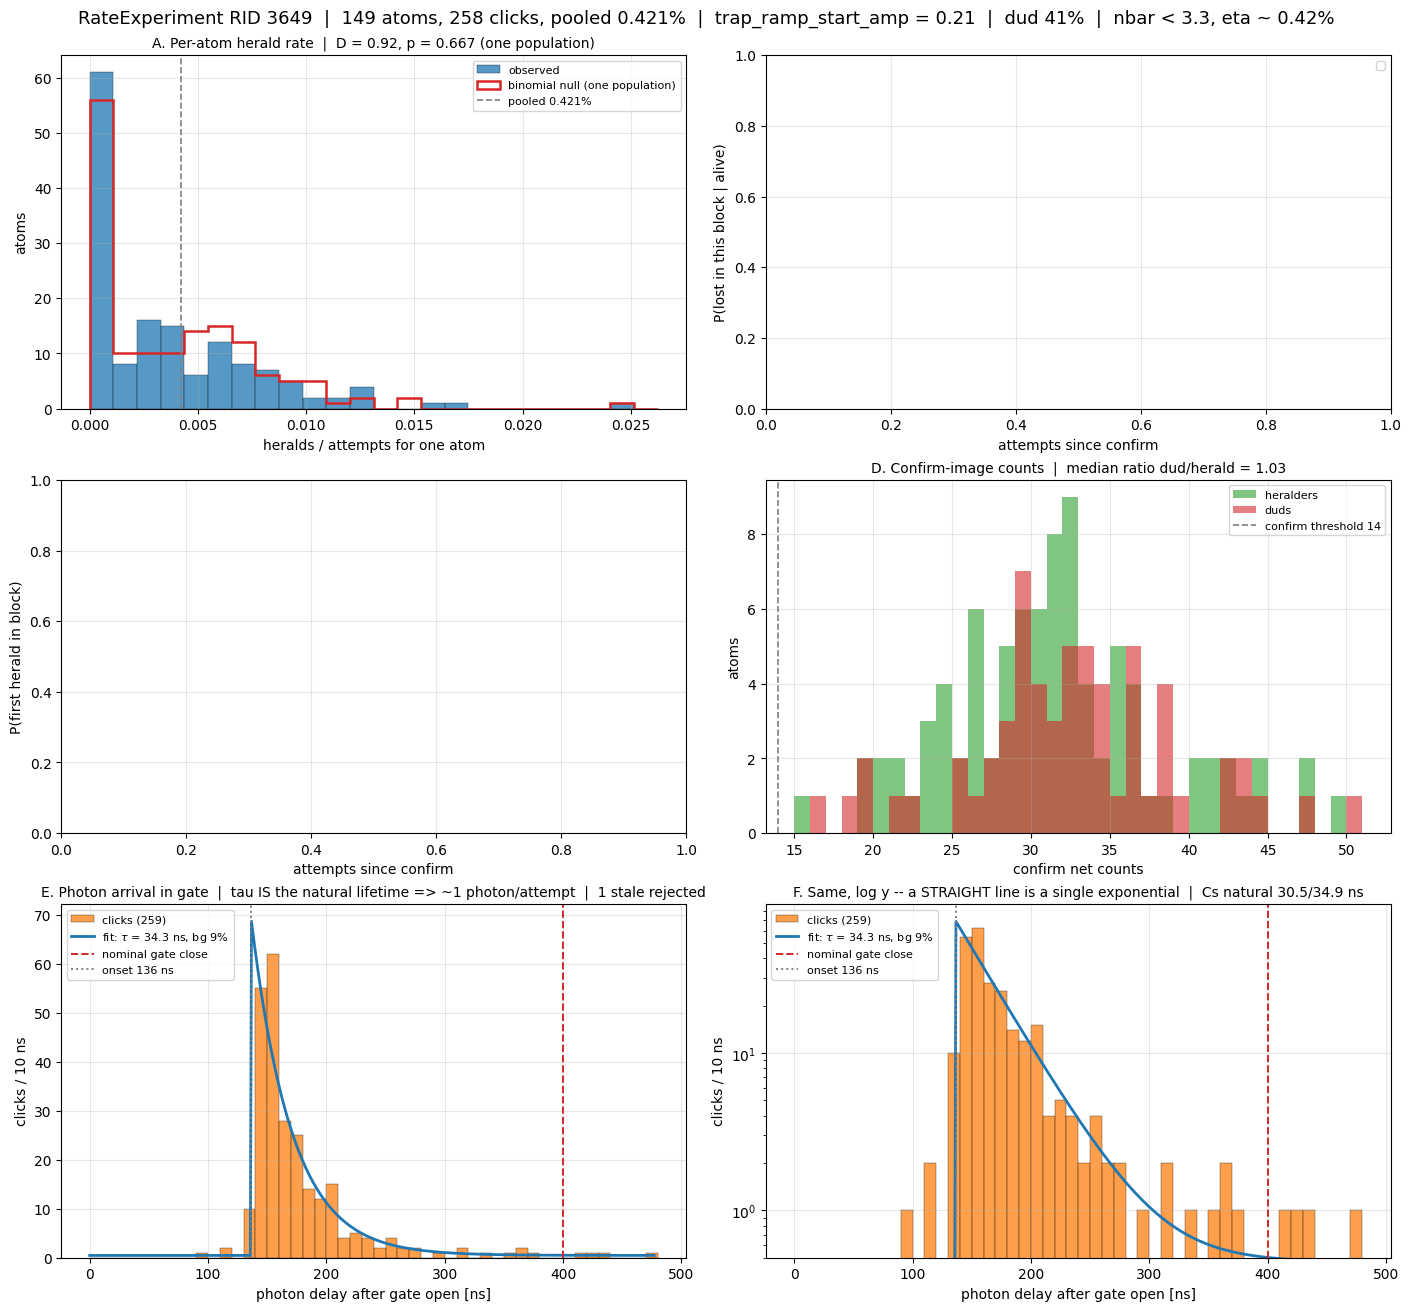

In [8]:
RID = None   # None = latest instrumented run; or e.g. 3643

fig = analyze(find_run(RID))

## The headline numbers

If the two-rate check agrees, the whole system is **two numbers** and there is no third mechanism to hunt: the only ways to improve heralding are to raise $p$ or lower $h$.

In [ ]:
r = summarize(find_run(RID), verbose=False)
od, hz, tr, fl = r["overdispersion"], r["hazard"], r["two_rate"], r["flatness"]

print("RID %s | %d atoms | %d clicks | trap_ramp_start_amp = %s"
      % (r["rid"], r["n_atoms"], r["clicks"], r["trap_start"]))
if r["meta"].get("block_inferred"):
    print("   run still in progress (no expid): survival-check block inferred as"
          " %s from the completed lifetimes" % r["block"])
print()

# Every block-based test needs the survival-check block AND enough completed
# lifetimes, so on a run that has only just started they are still None. Report
# that rather than raising -- this cell used to die with TypeError on live runs.
print("herald rate p    : %.4f %%/attempt" % (100 * r["p_pooled"]))
if tr is None:
    print("loss hazard h    : not available yet -- needs completed lifetimes")
    print("observed duds    : %.1f %%  (no h yet, so no h/(h+p) prediction)"
          % (100 * r["dud_frac"]))
else:
    print("loss hazard h    : %.4f %%/attempt" % (100 * tr["h_per_attempt"]))
    print("h/(h+p)          : %.1f %%  predicted duds" % (100 * tr["dud_predicted"]))
    print("observed duds    : %.1f %% +- %.1f %%"
          % (100 * tr["dud_observed"], 100 * tr["dud_se"]))
print()
if od is None:
    print("one population?  : not available yet")
else:
    print("one population?  : D = %.3f, bootstrap p = %.3f  -> %s"
          % (od["D"], od["p_value"],
             "OVERDISPERSED" if od["overdispersed"] else "one population"))
if hz is None:
    print("early extra loss?: not available yet")
else:
    print("early extra loss?: first block %.3f vs later %.3f (%+.1f sigma) -> %s"
          % (hz["h_first"], hz["h_later"], hz["z_first"],
             "EXCESS" if hz["early_loss"] else "none"))
if fl is None:
    print("warm-up?         : not available yet")
else:
    print("warm-up?         : chi2/dof = %.2f -> %s"
          % (fl["chi2_red"], "flat (no warm-up)" if fl["flat"] else "NOT flat"))

## Is the herald ONE photon? (sections 6-7)

These two tests are about the **photon**, not the atom, and together they settle what the ~0.4 %/attempt actually is.

- **Arrival shape.** `click_delay_ns` records where inside the collection gate each photon landed. An exponential at the Cs natural lifetime (D2 30.5 ns, D1 34.9 ns) means the atom emits **one** photon and is then pumped dark -- even though `exc_beam_duration_mu` drives it for ~10 lifetimes (300 ns). Flat across the gate would mean multi-photon scattering or background instead. This needs **no detection efficiency**: it is a shape, not a rate.
- **Coincidences.** `n_coincidences` counts the two-detector events the XOR herald discards. They cap the emitted photon number $ar n$ with no efficiency assumption, and they are what excludes the alternative reading of the in-gate doubles.

Measured on RID 3646: onset 135 ns, $	au$ = 36 ns, **0 coincidences in 85,380 attempts**. So $ar n pprox 1$, and therefore **$p$ IS the collection+detection efficiency** -- the heralding rate is collection-limited, and the only knobs are more collected light or a lower loss hazard $h$.

### The onset is at ~135 ns, not 0

Do not read that as a mistimed gate. The emission *starts* 135 ns after gate open and the captured tail runs ~8 $	au$, so the gate holds the whole burst; `exc_spcm_gate_offset_mu` is correctly calibrated. Clicks **past** the nominal gate close are expected too -- the input gate's effective window sits ~65 ns later in gateware than the timestamp reference, so the delay axis is shifted, not the shape.

### Stale reads

Negative delays are **not** early photons. `timestamp_mu` returns only the FIRST edge in a gate, so a second edge (an SPCM afterpulse 20-50 ns later) survives in the input FIFO and a *later* attempt reads it carrying its old, milliseconds-stale timestamp. `photon_profile()` checks each one against the previous same-detector click instead of assuming the mechanism. Here they merely misattribute a herald; in `parity.py` the same value feeds `at_mu(click + 2000)`, scheduling an MW edge in the **past** -> RTIOUnderflow.

In [ ]:
ph, co = r["photon"], r["coinc"]
fit = ph["fit"] if ph else None

if fit and not fit["flat"]:
    print("arrival shape : onset %.0f ns, tau = %.1f ns [%.1f-%.1f], flat component %.0f %%"
          % (fit["t0"], fit["tau"], fit["tau_lo"], fit["tau_hi"], 100 * fit["w"]))
    print("                Cs natural D2 30.5 / D1 34.9 ns  ->  %s"
          % ("ONE photon per attempt" if ph.get("tau_is_natural")
             else "NOT the natural lifetime"))
    if "bg_frac" in ph:
        print("uniform bg    : %.1f %% of heralds (95%% UL %.1f %%), from the %.0f ns "
              "guard window below the onset" % (100 * ph["bg_frac"],
                                                100 * ph["bg_frac_ul"], ph["pre_hi"]))
        if ph.get("tail_is_late"):
            print("                the fitted %.0f %% flat component is LATE-weighted "
                  "(re-excitation tail), not dark counts" % (100 * fit["w"]))
elif fit:
    print("arrival shape : FLAT -> multi-photon scattering or background")

if co:
    if co["nbar_max"] is not None:
        print("coincidences  : 0 of %d attempts -> nbar < %.1f emitted photons/attempt "
              "(95%% CL)" % (co["attempts"], co["nbar_max"]))
    else:
        print("coincidences  : %d -> nbar ~ %.1f photons/attempt"
              % (co["n_coinc"], co["nbar_est"]))
    print("=> eta        : %.3f %% per emitted photon -- the rate is COLLECTION-LIMITED"
          % (100 * r["p_pooled"]))

if ph and ph["n_stale"]:
    print()
    print("stale reads   : %d of %d clicks (%.2f %%); mechanism %s"
          % (ph["n_stale"], ph["n_clicks"], 100 * ph["stale_frac"],
             "CONFIRMED against the click record" if ph["stale_confirmed"]
             else "NOT confirmed -- inspect ph['stale_pairs']"))
    print("                parity impact: ~1 herald in %.0f would schedule its MW pulse "
          "in the past" % (1.0 / ph["stale_frac"]))

## Improvement budget

What the duds and the clicks-per-atom would become if you changed $p$ or $h$. Useful for deciding which knob is worth the effort — and note that **parity pays this tax on every measurement**, because every parity herald is on a freshly confirmed atom.

In [ ]:
if tr is None:
    print("No loss hazard h yet -- the run needs completed lifetimes (atoms that")
    print("were seen to die at a survival check), so this budget cannot be built.")
    print("Herald rate so far: p = %.4f %%/attempt." % (100 * r["p_pooled"]))
else:
    p0, h0 = tr["p_per_attempt"], tr["h_per_attempt"]
    print("            duds = h/(h+p)   clicks/atom = p/h")
    print("now        : %5.1f%%          %.2f" % (100 * h0 / (h0 + p0), p0 / h0))
    for f, lab in ((0.5, "halve h"), (0.25, "quarter h")):
        h = h0 * f
        print("%-11s: %5.1f%%          %.2f" % (lab, 100 * h / (h + p0), p0 / h))
    for f, lab in ((2.0, "double p"), (4.0, "4x p")):
        p = p0 * f
        print("%-11s: %5.1f%%          %.2f" % (lab, 100 * h0 / (h0 + p), p / h0))

## Trap-depth series (and any other scanned argument)

`compare_runs()` uses the per-atom metrics, so it only covers runs from 2026-10-22 on. For a scan that started earlier — like `trap_ramp_start_amp` 0.21 → 0.18 → 0.15 — use `compare_runs_legacy()`, which works from `trials_per_click` (present in every run) and pools by argument value with a proper binomial error.

In [ ]:
_ = compare_runs_legacy(arg="trap_ramp_start_amp", min_rid=3630)

In [ ]:
# Per-atom metrics, for runs that have them (instrumented runs only).
_ = compare_runs(arg="trap_ramp_start_amp", n_boot=400)

## Reading the result

1. **Two-rate check first.** If `h/(h+p)` reproduces the observed dud fraction, the duds are fully explained and *no* heterogeneity mechanism is needed. Chasing beam overlap, two-atom loads or warm-ups after that is chasing a residual that isn't there.
2. **Overdispersion $D\approx1$ is a strong negative result**, not a null one. It rules out *any* story where some confirmed atoms are intrinsically bad heralders — spatial overlap included.
3. **"Lost right after trapping" has a geometry subtlety.** The confirm image happens *after* `t_MOT_dissipation` and the imaging PGC, so an atom lost while the MOT disperses **fails confirm and never appears in this file.** What the first hazard block can see is loss between confirm and the first survival check — dominated by the one-time trap ramp-down. If you want to test MOT-dissipation loss, the observable is the **confirm-fail rate** (load cycles whose confirm image is empty), not the dud fraction.
4. **The hazard grid is coarse.** Loss is only detected at the survival check, every `Check_img_every` attempts (48 here, not the ~12 it is easy to assume — `max_excitation_cycles` is the inner block, 4). So the first hazard point averages over the ramp-down *and* 48 attempts.
5. **The photon tests are the end of the line for $p$.** Section 6 shows the herald is a single natural-lifetime photon and section 7 caps $ar n$, so $p$ is not low because of a bad excitation pulse, background, or a clipped gate -- it is the collection efficiency. Stop tuning the excitation and go after collected solid angle, or after $h$.
6. **Per-atom herald rates are survivorship-biased** by construction: an atom that clicked proved it couples. That is why the comparison must be against the binomial null at the *pooled* rate, which is what $D$ does.